# micrograd à la main

Suivi de [The spelled-out intro to neural networks and backpropagation: building micrograd](https://www.youtube.com/watch?v=VMj-3S1tku0) (Andrej Karpathy).

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import os
os.environ["PATH"] += r";C:\Program Files\Graphviz\bin"


In [2]:
def f(x):
    return 3*x**2 - 4*x + 5

In [3]:
f(2.0)

9.0

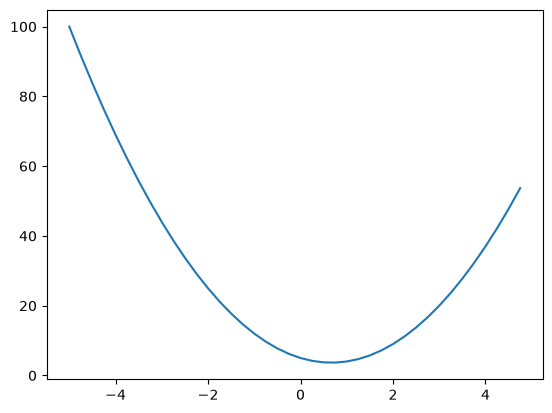

In [4]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [5]:
h = 0.00000001
x = 2.0
(f(x+h) - f(x)) / h

7.999999951380232

In [6]:
# getting more complex
a = 2.0
b = -3.0
c = 10.0
d = a*b + c
print(d)

4.0


In [7]:
h = 0.0001

#inputs
a = 2.0
b = -3.0
c = 10.0

d1 = a*b + c
c += h
d2 = a*b + c

print(('d1', d1))
print(('d2', d2))
print('pente', (d2-d1)/h) # dérivé de d par rapport à d(a) = b


('d1', 4.0)
('d2', 4.0001)
pente 0.9999999999976694


In [ ]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        # represent the derivative of the output with respect to some Value()
        self.backward = lambda: None
        # back propagation grad
        self._prev = set(_children)
        # valeur par Value(), children & set sont 2 classes vides
        # valeur par + ou * , feed in Value()
        self._op = _op
        # what expression created this Value() ('+', '*', etc.)
        self.label = label

    def __repr__(self):
        return f'value(data = {self.data}, op = {self._op})'
    # prints nicely when we call print on a Value object

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
    
        def _backward():
            self.grad  += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
    
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')

        def _backward():
          self.grad  += other.data * out.grad
          other.grad += self.data * out.grad
        out._backward = _backward
      
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')

        def _backward():
         self.grad += (1 - t**2) * out.grad
        out._backward = _backward
    
        return out

    def backward(self):
    
      topo = []
      visited = set()
      def build_topo(v):
        if v not in visited:
          visited.add(v)
          for child in v._prev:
            build_topo(child)
          topo.append(v)
      build_topo(self)
    
      self.grad = 1.0
      for node in reversed(topo):
        node._backward()
    
    
    

a = Value(2.0, label='a')
b = Value(-3.0, label='b')
c = Value(10.0, label='c')
a + b # a.__add__(b)
a * b + c # a.__mul__(b).__add__(c)

e = a * b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d * f; L.label = 'L'

print (d._prev, d._op, d)
L

{value(data = 10.0, op = ), value(data = -6.0, op = *)} + value(data = 4.0, op = +)


value(data = -8.0, op = *)

In [105]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in the graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        #for any value in the graph, create a rectangular ('record') for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some opetation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
        
    return dot

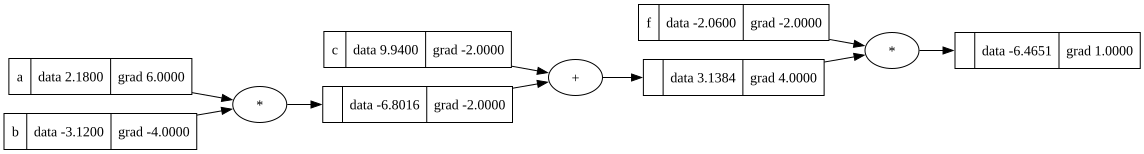

In [102]:
draw_dot(L)
# grad = derivative of L in respect to L
# How much is L going to change if i nodge it's value by h ?

In [97]:
a.data += 0.01 * a.grad
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f.data += 0.01 * f.grad

e = a * b
d = e + c
L = d * f
print(L.data)

-6.465104000000002


In [98]:
'''
(dL)   (dL)   dd    de
 --  =  --  * --  * --
(da)    dd    de   (da)

de/da ? e = a*b  gives us de/da = b
'''
a.grad = -3.0 * -2.0  * 1
b.grad = 2.0 * -2.0 * 1

In [99]:
#dd / dc = 1.0
#dd / de = 1.0
'''
(f(x+h) - f(x)) / h
dL / dc = c + e -> 1.0
How is L sensitive to c ?

(dL)   (dL)   dd
 --  =  --  * --
(dc)    dd   (dc)

derivative '+' = 1 so it routes the gradient to both children

'''
c.grad = -2.0
e.grad = -2.0



In [100]:
#dL/dd = ? f derivative of L with
# d.data += h & f.data += h

L.grad = 1.0
d.grad = 4.0
f.grad = -2.0

In [101]:
def lol():

    h = 0.001

    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a * b; e.label = 'e'
    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')
    L = d * f; L.label = 'L'
    L1 = L.data



    a = Value(2.0, label='a')
    b = Value(-3.0, label='b')
    c = Value(10.0, label='c')
    e = a * b; e.label = 'e'

    d = e + c; d.label = 'd'
    f = Value(-2.0, label='f')

    L = d * f; L.label = 'L'
    L2 = L.data

    print((L2 - L1)/h)

lol()

0.0


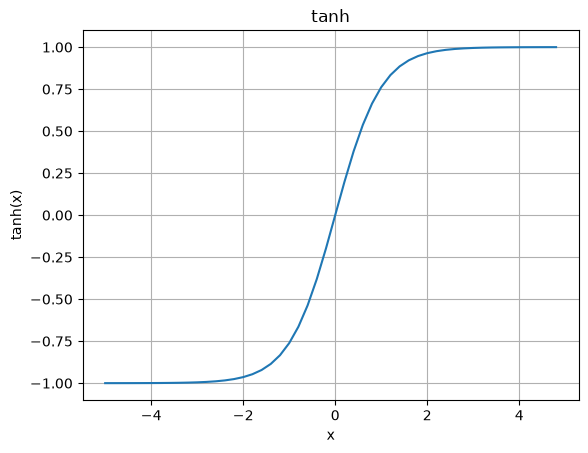

In [103]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid(); plt.title('tanh'); plt.xlabel('x'); plt.ylabel('tanh(x)'); plt.show()

In [156]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'



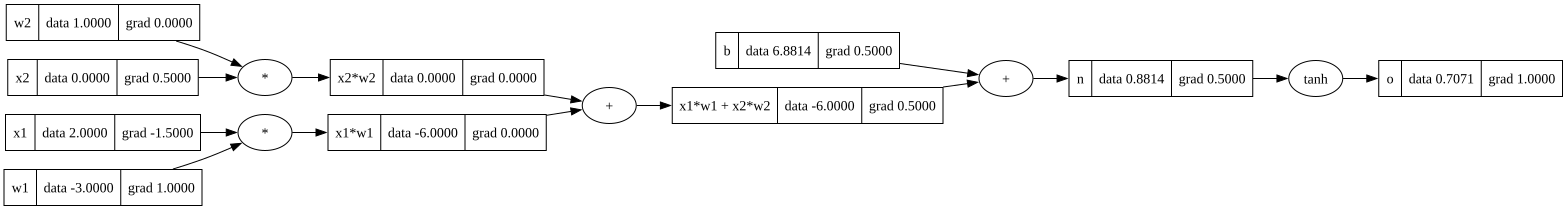

In [175]:
draw_dot(o)

In [176]:
topo = []
visited = set()
def build_topo(v):
  if v not in visited:
    visited.add(v)
    for child in v._prev:
      build_topo(child)
    topo.append(v)
build_topo(o)
topo

[value(data = 0.0, op = ),
 value(data = 1.0, op = ),
 value(data = 0.0, op = *),
 value(data = 2.0, op = ),
 value(data = -3.0, op = ),
 value(data = -6.0, op = *),
 value(data = -6.0, op = +),
 value(data = 6.881373587019543, op = ),
 value(data = 0.8813735870195432, op = +),
 value(data = 0.7071067811865476, op = tanh)]

In [174]:
x1w1._backward()
x2w2._backward()

In [151]:
n.grad = 0.5

In [152]:
o.grad = 1.0

In [146]:
1 - o.data ** 2

8.659739592076221e-15

In [ ]:
# o = tanh(h)
# do/dn = 1 - o**2

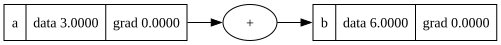

In [ ]:
a = Value(3.0, label='a')
b = a + a   ; b.label = 'b'
# PROBLÈME = overwriting du gradient de self + other ==
b.backward()
draw_dot(b)

In [185]:
a = Value(-2.0, label='a')
b = Value(3.0, label='b')
d = a * b    ; d.label = 'd'
e = a + b    ; e.label = 'e'
f = d * e    ; f.label = 'f'

f.backward()



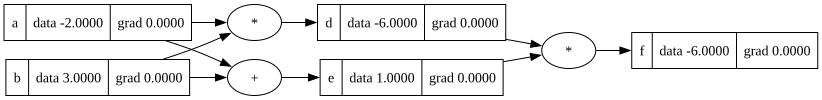

In [188]:
draw_dot(f)